# Portion 3 — Self-supervised spatiotemporal pretraining (GPU: A100 recommended)
**Input:** `portion1_outputs/` (frames) and `portion2_outputs/targets_per_frame.csv` (only for *evaluating* the frozen representations).
**Output:** `portion3_outputs/` — encoder checkpoints, per-frame embeddings for Portion 4, probe results, figures.

| ID | Model | Frames | Masking | Temporal InfoNCE | Frame order |
|---|---|---|---|---|---|
| **B0** | random initialisation (no pretraining) | 8 | – | – | – |
| **B2** | frame-wise MAE | 1 | random 75 % | – | – |
| **B3** | temporal (tube) MAE | 8 | tube 90 % | – | true |
| **B4** | temporal MAE + temporal-consistency InfoNCE (**proposed**) | 8 | tube 90 % | ✓ | true |
| **B5** | B4 with shuffled frame order (**control**: does time order matter?) | 8 | tube 90 % | ✓ | shuffled |

**Leakage rule:** every encoder is pretrained **only on the training concentrations of its split** (5 LOCO folds + P1 + P1r).
The held-out movie is never seen, not even without labels.

**Speed design:** the whole dataset (all movies at 5 nm/px, float16, ~0.4 GB) lives **on the GPU**; clips, crops and augmentations
are built on the GPU (no DataLoader); bf16 autocast + Flash/SDPA attention + fused AdamW. Every run checkpoints to Drive and **resumes**
after a Colab disconnect. Expected cost on an A100: ~6–10 min per run, 28 runs ≈ 3–5 GPU-hours (printed ETA after the first run).

Without a GPU the notebook automatically switches to `QUICK` mode (tiny model, few steps) so every cell can still be checked end to end.

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Imports & device ----------------------------------------------------------
import os, json, time, math, glob, shutil, warnings, platform, random, zlib
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    BF16 = torch.cuda.is_bf16_supported()
    print('GPU:', torch.cuda.get_device_name(0), f'| {torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB | bf16:', BF16)
else:
    BF16 = False
    print('No GPU found -> QUICK mode (tiny model). Use Runtime > Change runtime type > A100 GPU for the real run.')
AMP_DTYPE = torch.bfloat16 if BF16 else torch.float16
USE_AMP = DEVICE.type == 'cuda'
print('torch', torch.__version__, '| numpy', np.__version__, '| pandas', pd.__version__, '| device', DEVICE)

GPU: NVIDIA A100-SXM4-40GB | 42 GB | bf16: True
torch 2.11.0+cu130 | numpy 2.1.3 | pandas 2.2.3 | device cuda


In [3]:
# ---- 2. Configuration ---------------------------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
P1_DIR = os.path.join(DATA_DIR, 'portion1_outputs')
P2_DIR = os.path.join(DATA_DIR, 'portion2_outputs')
OUT_DIR = os.path.join(DATA_DIR, 'portion3_outputs')
FIG = os.path.join(OUT_DIR, 'figures'); RUNS = os.path.join(OUT_DIR, 'runs'); EMB = os.path.join(OUT_DIR, 'embeddings')
for d in [OUT_DIR, FIG, RUNS, EMB]:
    os.makedirs(d, exist_ok=True)

QUICK = ((DEVICE.type != 'cuda') or os.environ.get('HSAFM_QUICK', '0') == '1') and os.environ.get('HSAFM_FORCE_FULL', '0') != '1'

VARIANTS  = ['B2', 'B3', 'B4', 'B5']          # pretrained variants (B0 = random init, needs no training)
SPLITS    = 'all'                             # 'all' = 5-6 LOCO folds + P1 + P1r, or a list such as ['LOCO_6nM']
if os.environ.get('HSAFM_SPLITS'): SPLITS = os.environ['HSAFM_SPLITS'].split(',')   # (local-testing override)
NM_PER_PX = 5.0                               # every frame is resampled to 5 nm/px (400-px frames: 2x2 mean)
TARGET_DT = 2.0                               # seconds between clip frames (1 fps session -> stride 2, 0.5 fps -> stride 1)
T_FRAMES  = 8                                 # frames per clip
MAX_OFFSET = 4                                # max offset (in clip steps, x TARGET_DT s) between the two clips of a positive pair
H_CLIP, H_SCALE = 1.0, 1.0                    # input = (clip(h, -1, 4) - H_CLIP) / H_SCALE  -> fixed PHYSICAL scaling (no data statistics)

if not QUICK:   # ---- real run (A100) ----
    CROP, PATCH, TUBELET = 192, 16, 2
    ENC_DIM, ENC_DEPTH, ENC_HEADS = 384, 12, 6          # ViT-S
    DEC_DIM, DEC_DEPTH, DEC_HEADS = 192, 4, 3
    STEPS, BATCH_PAIRS, BATCH_FRAMES = 6000, 64, 256
    LR, WD, WARMUP = 3e-4, 0.05, 300
    EMB_BATCH = 128
else:           # ---- smoke test (CPU) ----
    CROP, PATCH, TUBELET = 96, 16, 2
    ENC_DIM, ENC_DEPTH, ENC_HEADS = 96, 3, 3
    DEC_DIM, DEC_DEPTH, DEC_HEADS = 64, 1, 2
    STEPS, BATCH_PAIRS, BATCH_FRAMES = 25, 4, 8
    LR, WD, WARMUP = 1e-3, 0.05, 5
    EMB_BATCH = 32
STEPS = int(os.environ.get('HSAFM_STEPS', STEPS))
if os.environ.get('HSAFM_BATCH'):                                   # (local-testing override)
    BATCH_PAIRS = BATCH_FRAMES = EMB_BATCH = int(os.environ['HSAFM_BATCH'])
MASK_TUBE, MASK_FRAME = 0.90, 0.75
LAMBDA_NCE, TAU = 0.5, 0.1
CKPT_EVERY = 500
LOG_EVERY = max(1, min(50, STEPS // 10))
SEED = 0
print(f'QUICK={QUICK} | crop {CROP}px ({CROP*NM_PER_PX:.0f} nm) | ViT {ENC_DIM}x{ENC_DEPTH} | steps {STEPS} | pairs/batch {BATCH_PAIRS}')

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
seed_all(SEED)

QUICK=False | crop 192px (960 nm) | ViT 384x12 | steps 6000 | pairs/batch 64


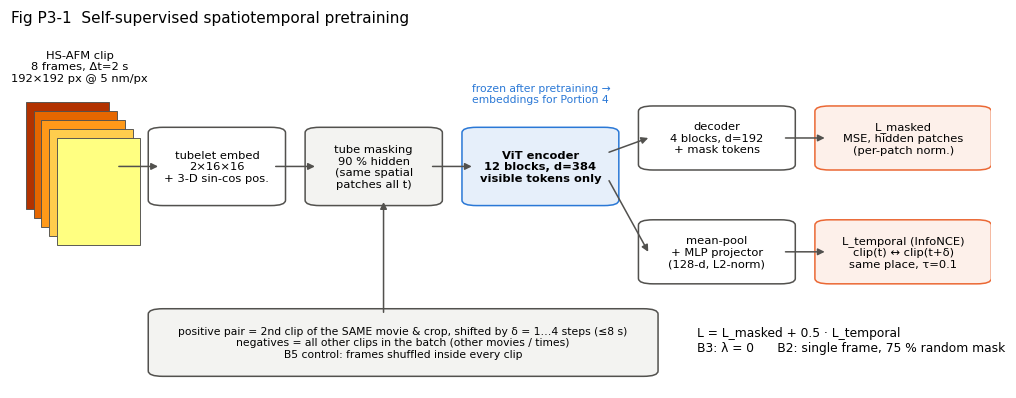

In [4]:
# ---- 3. Figure style + architecture diagram (Fig P3-1) ------------------------------------------------
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
                     'lines.linewidth': 1.6, 'legend.frameon': False})
_ALL = ['2nM', '4nM', '6nM', '8nM', '10nM', '12nM']
CCOL = {c: plt.get_cmap('Blues')(0.35 + 0.6 * i / 5) for i, c in enumerate(_ALL)}
VCOL = {'B0': '#9a9a9a', 'B2': '#1baf7a', 'B3': '#eb6834', 'B4': '#2a78d6', 'B5': '#eda100'}   # validated categorical order
VNAME = {'B0': 'B0 random init', 'B2': 'B2 frame MAE', 'B3': 'B3 temporal MAE',
         'B4': 'B4 temporal MAE + InfoNCE (proposed)', 'B5': 'B5 shuffled-time control'}

def box(ax, x, y, w, h, text, fc='#ffffff', ec='#52514e', fs=7.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.01,rounding_size=0.015', fc=fc, ec=ec, lw=1.0))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, weight='bold' if bold else 'normal', wrap=True)

def arrow(ax, x0, y0, x1, y1, color='#52514e'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=color, lw=1.0, shrinkA=0, shrinkB=0))

fig, ax = plt.subplots(figsize=(11.5, 4.2)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
# clip stack
for k in range(5):
    ax.add_patch(plt.Rectangle((0.015 + 0.008 * k, 0.50 - 0.025 * k), 0.085, 0.30, fc=plt.get_cmap('afmhot')(0.35 + 0.1 * k), ec='#52514e', lw=0.6))
ax.text(0.07, 0.86, f'HS-AFM clip\n{T_FRAMES} frames, Δt={TARGET_DT:.0f} s\n{CROP}×{CROP} px @ {NM_PER_PX:.0f} nm/px', ha='center', fontsize=7.5)
box(ax, 0.15, 0.52, 0.12, 0.20, f'tubelet embed\n{TUBELET}×{PATCH}×{PATCH}\n+ 3-D sin-cos pos.')
box(ax, 0.31, 0.52, 0.12, 0.20, f'tube masking\n{int(MASK_TUBE*100)} % hidden\n(same spatial\npatches all t)', fc='#f3f3f1')
box(ax, 0.47, 0.52, 0.14, 0.20, f'ViT encoder\n{ENC_DEPTH} blocks, d={ENC_DIM}\nvisible tokens only', fc='#e6effa', ec='#2a78d6', bold=True)
box(ax, 0.65, 0.62, 0.14, 0.16, f'decoder\n{DEC_DEPTH} blocks, d={DEC_DIM}\n+ mask tokens')
box(ax, 0.83, 0.62, 0.16, 0.16, 'L_masked\nMSE, hidden patches\n(per-patch norm.)', fc='#fdf0ea', ec='#eb6834')
box(ax, 0.65, 0.30, 0.14, 0.16, 'mean-pool\n+ MLP projector\n(128-d, L2-norm)')
box(ax, 0.83, 0.30, 0.16, 0.16, 'L_temporal (InfoNCE)\nclip(t) ↔ clip(t+δ)\nsame place, τ=0.1', fc='#fdf0ea', ec='#eb6834')
arrow(ax, 0.11, 0.62, 0.15, 0.62); arrow(ax, 0.27, 0.62, 0.31, 0.62); arrow(ax, 0.43, 0.62, 0.47, 0.62)
arrow(ax, 0.61, 0.66, 0.65, 0.70); arrow(ax, 0.79, 0.70, 0.83, 0.70)
arrow(ax, 0.61, 0.58, 0.65, 0.38); arrow(ax, 0.79, 0.38, 0.83, 0.38)
box(ax, 0.15, 0.04, 0.50, 0.17, f'positive pair = 2nd clip of the SAME movie & crop, shifted by δ = 1…{MAX_OFFSET} steps (≤{MAX_OFFSET*TARGET_DT:.0f} s)\n'
    f'negatives = all other clips in the batch (other movies / times)\nB5 control: frames shuffled inside every clip', fs=7, fc='#f3f3f1')
arrow(ax, 0.38, 0.21, 0.38, 0.52)
ax.text(0.70, 0.10, f'L = L_masked + {LAMBDA_NCE} · L_temporal\nB3: λ = 0      B2: single frame, 75 % random mask', fontsize=8, ha='left')
ax.text(0.47, 0.80, 'frozen after pretraining →\nembeddings for Portion 4', fontsize=7, color='#2a78d6', ha='left')
ax.set_title('Fig P3-1  Self-supervised spatiotemporal pretraining', fontsize=10, loc='left')
fig.savefig(os.path.join(FIG, 'figP3_1_architecture.png'), bbox_inches='tight'); plt.show()

In [5]:
# ---- 4. Build the 5 nm/px dataset cache (CPU, runs once) ---------------------------------------------------
frames = pd.read_csv(os.path.join(P1_DIR, 'frames_all.csv'))
sessions = pd.read_csv(os.path.join(P1_DIR, 'sessions.csv'))
splits_p1 = json.load(open(os.path.join(P1_DIR, 'splits.json')))
targets = pd.read_csv(os.path.join(P2_DIR, 'targets_per_frame.csv'))
conc_order = lambda c: float(str(c).replace('nM', ''))
kept = frames[~frames.exclude.astype(bool)].copy()
kept = kept.sort_values(['conc_nM', 'session', 't_rel_s']).reset_index(drop=True)
CONCS = sorted(kept.conc.unique(), key=conc_order)

cache_npy = os.path.join(OUT_DIR, 'dataset_5nm_f16.npy')
cache_idx = os.path.join(OUT_DIR, 'dataset_index.csv')
need = True
if os.path.exists(cache_npy) and os.path.exists(cache_idx):
    old = pd.read_csv(cache_idx)
    need = list(old.frame_id) != list(kept.frame_id)
if need:
    t0 = time.time()
    side = None; arrs = []
    for (sf), g in kept.groupby('stack_file', sort=False):
        st = np.load(os.path.join(P1_DIR, sf), mmap_mode='r')
        a = np.asarray(st[g.stack_idx.values.astype(int)], dtype=np.float32)
        nmpx = float(g.nm_per_px.iloc[0]); f = int(round(NM_PER_PX / nmpx))
        if f > 1:
            n, h, w = a.shape
            a = a[:, :h // f * f, :w // f * f].reshape(n, h // f, f, w // f, f).mean(axis=(2, 4))
        arrs.append((g.index.values, a.astype(np.float16)))
    sizes = {a.shape[1:] for _, a in arrs}
    assert len(sizes) == 1, f'frames have different sizes after resampling: {sizes}'
    X = np.zeros((len(kept),) + sizes.pop(), np.float16)
    for ix, a in arrs:
        X[ix] = a
    np.save(cache_npy, X)
    kept[['frame_id', 'conc', 'session', 't_rel_s']].to_csv(cache_idx, index=False)
    print(f'built dataset cache {X.shape} in {time.time()-t0:.0f}s')
else:
    print('dataset cache up to date')

# clip bookkeeping: position of every frame inside its session and the frame stride that gives ~TARGET_DT seconds
kept['pos'] = kept.groupby('session').cumcount()
dt_sess = kept.groupby('session').t_rel_s.apply(lambda s: float(np.median(np.diff(s.values))) if len(s) > 1 else TARGET_DT)
kept['stride'] = kept.session.map(lambda s: max(1, int(round(TARGET_DT / max(dt_sess[s], 1e-3)))))
SESS = {}
for s, g in kept.groupby('session', sort=False):
    SESS[s] = dict(gidx=g.index.values, conc=g.conc.iloc[0], stride=int(g.stride.iloc[0]))
print(pd.DataFrame([dict(session=s, conc=v['conc'], frames=len(v['gidx']), stride=v['stride'],
                         dt_s=round(dt_sess[s], 2), clip_span_s=round((T_FRAMES - 1) * v['stride'] * dt_sess[s], 1))
                    for s, v in SESS.items()]).to_string(index=False))

dataset cache up to date
      session conc  frames  stride  dt_s  clip_span_s
 2nM_s0_200px  2nM     597       2  1.03         14.4
 4nM_s0_200px  4nM     596       2  1.03         14.4
 4nM_s1_400px  4nM     290       1  2.03         14.2
 6nM_s0_200px  6nM     540       2  1.03         14.4
 6nM_s1_400px  6nM     257       1  2.03         14.2
 8nM_s0_200px  8nM     566       2  1.03         14.4
 8nM_s1_400px  8nM     292       1  2.03         14.2
10nM_s0_200px 10nM     597       2  1.03         14.4
10nM_s1_400px 10nM     301       1  2.03         14.2


In [6]:
# ---- 5. Put the dataset on the device + GPU clip sampler ----------------------------------------------------
X_np = np.load(cache_npy, mmap_mode='r')
H0, W0 = X_np.shape[1:]
X_dev = torch.from_numpy(np.ascontiguousarray(X_np)).to(DEVICE)      # (N, H0, W0) float16, nm
print(f'dataset on {DEVICE}: {tuple(X_dev.shape)}  {X_dev.numel()*2/1e9:.2f} GB')

def to_input(x):
    """nm -> network input with fixed physical scaling (mica -1, origami ~+1)."""
    return (x.float().clamp(-1.0, 4.0) - H_CLIP) / H_SCALE

def session_table(concs, T, max_off):
    """valid clip start positions for the given concentrations."""
    rows = []
    for s, v in SESS.items():
        if v['conc'] not in concs:
            continue
        span = (T - 1 + max_off) * v['stride']
        n_start = len(v['gidx']) - span
        if n_start > 0:
            rows.append((s, n_start))
    return rows

class ClipSampler:
    """Samples (pairs of) clips entirely on the device."""
    def __init__(self, concs, T, max_off, gen):
        self.T, self.max_off, self.g = T, max_off, gen
        rows = session_table(concs, T, max_off)
        if not rows:                                   # sessions too short for offsets -> no offset
            self.max_off = 0; rows = session_table(concs, T, 0)
        assert rows, f'no session long enough for {T}-frame clips in {concs}'
        self.sess = [r[0] for r in rows]
        w = np.array([r[1] for r in rows], float); self.p = w / w.sum()
        self.gidx = [np.asarray(SESS[s]['gidx']) for s in self.sess]
        self.stride = [SESS[s]['stride'] for s in self.sess]
        self.nstart = [r[1] for r in rows]

    def sample_idx(self, B):
        """returns two (B,T) global-index tensors: clip at t and clip at t+delta (same session)."""
        si = self.g.choice(len(self.sess), size=B, p=self.p)
        a_idx, b_idx = [], []
        for k in si:
            st = int(self.g.integers(0, self.nstart[k])); s = self.stride[k]
            d = int(self.g.integers(1, self.max_off + 1)) if self.max_off > 0 else 0
            pa = st + s * np.arange(self.T); pb = pa + d * s
            a_idx.append(self.gidx[k][pa]); b_idx.append(self.gidx[k][pb])
        return torch.as_tensor(np.stack(a_idx), device=DEVICE), torch.as_tensor(np.stack(b_idx), device=DEVICE)

def crop_aug(idx_list, crop, train=True, gen=None, shuffle_time=False):
    """idx_list: list of (B,T) index tensors that share crop & augmentation. Returns list of (B,1,T,crop,crop) inputs."""
    B, T = idx_list[0].shape
    if train:
        oy = torch.as_tensor(gen.integers(0, H0 - crop + 1, size=B), device=DEVICE)
        ox = torch.as_tensor(gen.integers(0, W0 - crop + 1, size=B), device=DEVICE)
        flips = torch.as_tensor(gen.integers(0, 2, size=(B, 3)), device=DEVICE).bool()
        gain = torch.as_tensor(gen.uniform(0.9, 1.1, size=B), device=DEVICE, dtype=torch.float32)
        perms = [torch.as_tensor(gen.permutation(T), device=DEVICE) for _ in range(B)] if shuffle_time else None
    else:
        oy = torch.full((B,), (H0 - crop) // 2, device=DEVICE); ox = torch.full((B,), (W0 - crop) // 2, device=DEVICE)
    ar = torch.arange(crop, device=DEVICE)
    rows = (oy[:, None] + ar)[:, None, :, None]; cols = (ox[:, None] + ar)[:, None, None, :]
    out = []
    for idx in idx_list:
        if train and shuffle_time:
            idx = torch.stack([idx[b][perms[b]] for b in range(B)])
        x = X_dev[idx[:, :, None, None], rows, cols]                       # (B,T,crop,crop)
        x = to_input(x)
        if train:
            x = torch.where(flips[:, 0, None, None, None], x.flip(-1), x)
            x = torch.where(flips[:, 1, None, None, None], x.flip(-2), x)
            x = torch.where(flips[:, 2, None, None, None], x.transpose(-1, -2), x)
            x = x * gain[:, None, None, None]
        out.append(x[:, None])
    return out

dataset on cuda: (4036, 200, 200)  0.32 GB


In [7]:
# ---- 6. Model: tubelet ViT-MAE with temporal InfoNCE head ------------------------------------------------------
def sincos_1d(n, d):
    pos = np.arange(n, dtype=np.float64)[:, None]
    omega = 1.0 / 10000 ** (np.arange(d // 2, dtype=np.float64) / (d // 2))
    a = pos * omega[None]
    return np.concatenate([np.sin(a), np.cos(a)], axis=1)

def sincos_3d(t, h, w, dim):
    """separable 3-D sin-cos position embedding, (t*h*w, dim)."""
    dt_ = 2 * (dim // 6); dh = 2 * (dim // 6); dw = dim - dt_ - dh
    et, eh, ew = sincos_1d(t, dt_), sincos_1d(h, dh), sincos_1d(w, dw if dw % 2 == 0 else dw - 1)
    if dw % 2: ew = np.concatenate([ew, np.zeros((w, 1))], 1)
    e = np.concatenate([np.repeat(et, h * w, 0), np.tile(np.repeat(eh, w, 0), (t, 1)), np.tile(ew, (t * h, 1))], 1)
    return torch.tensor(e, dtype=torch.float32)

class Block(nn.Module):
    def __init__(self, dim, heads, mlp=4.0):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.qkv, self.proj, self.h = nn.Linear(dim, dim * 3), nn.Linear(dim, dim), heads
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp)), nn.GELU(), nn.Linear(int(dim * mlp), dim))
    def forward(self, x):
        B, N, C = x.shape
        q, k, v = self.qkv(self.n1(x)).reshape(B, N, 3, self.h, C // self.h).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v)                      # Flash / memory-efficient attention when available
        x = x + self.proj(a.transpose(1, 2).reshape(B, N, C))
        return x + self.mlp(self.n2(x))

class VideoMAE(nn.Module):
    def __init__(self, T, tubelet, crop=CROP, patch=PATCH, dim=ENC_DIM, depth=ENC_DEPTH, heads=ENC_HEADS,
                 ddim=DEC_DIM, ddepth=DEC_DEPTH, dheads=DEC_HEADS, proj_dim=128):
        super().__init__()
        self.T, self.tt, self.p = T, tubelet, patch
        self.gt, self.gs = T // tubelet, crop // patch
        self.patch_embed = nn.Conv3d(1, dim, kernel_size=(tubelet, patch, patch), stride=(tubelet, patch, patch))
        self.register_buffer('pos', sincos_3d(self.gt, self.gs, self.gs, dim)[None], persistent=False)
        self.register_buffer('dpos', sincos_3d(self.gt, self.gs, self.gs, ddim)[None], persistent=False)
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)]); self.norm = nn.LayerNorm(dim)
        self.dec_embed = nn.Linear(dim, ddim); self.mask_token = nn.Parameter(torch.zeros(1, 1, ddim))
        self.dblocks = nn.ModuleList([Block(ddim, dheads) for _ in range(ddepth)]); self.dnorm = nn.LayerNorm(ddim)
        self.head = nn.Linear(ddim, tubelet * patch * patch)
        self.proj = nn.Sequential(nn.Linear(dim, dim), nn.GELU(), nn.Linear(dim, proj_dim))
        nn.init.normal_(self.mask_token, std=0.02); self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def patchify(self, x):                     # (B,1,T,H,W) -> (B, N, tt*p*p) in token order (t, h, w)
        B = x.shape[0]; tt, p, gt, gs = self.tt, self.p, self.gt, self.gs
        x = x.reshape(B, gt, tt, gs, p, gs, p).permute(0, 1, 3, 5, 2, 4, 6)
        return x.reshape(B, gt * gs * gs, tt * p * p)

    def unpatchify(self, y):
        B = y.shape[0]; tt, p, gt, gs = self.tt, self.p, self.gt, self.gs
        y = y.reshape(B, gt, gs, gs, tt, p, p).permute(0, 1, 4, 2, 5, 3, 6)
        return y.reshape(B, 1, gt * tt, gs * p, gs * p)

    def make_mask(self, B, ratio, tube, gen_t):
        S, N = self.gs * self.gs, self.gt * self.gs * self.gs
        if tube:                                # same spatial positions hidden in every temporal slice
            keep_s = max(1, int(round(S * (1 - ratio))))
            noise = torch.rand(B, S, device=self.pos.device, generator=gen_t)
            ids_s = noise.argsort(1)[:, :keep_s]
            ids_keep = (ids_s[:, None, :] + S * torch.arange(self.gt, device=ids_s.device)[None, :, None]).reshape(B, -1)
        else:
            keep = max(1, int(round(N * (1 - ratio))))
            ids_keep = torch.rand(B, N, device=self.pos.device, generator=gen_t).argsort(1)[:, :keep]
        mask = torch.ones(B, N, device=ids_keep.device); mask.scatter_(1, ids_keep, 0.0)
        return ids_keep.sort(1).values, mask

    def encode(self, x, ids_keep=None):
        tok = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos
        if ids_keep is not None:
            tok = torch.gather(tok, 1, ids_keep[..., None].expand(-1, -1, tok.shape[-1]))
        for b in self.blocks:
            tok = b(tok)
        return self.norm(tok)

    def forward_mae(self, x, ratio, tube, gen_t):
        B = x.shape[0]
        ids_keep, mask = self.make_mask(B, ratio, tube, gen_t)
        lat = self.encode(x, ids_keep)
        d = self.dec_embed(lat); N = mask.shape[1]
        full = self.mask_token.expand(B, N, -1).clone().to(d.dtype)
        full.scatter_(1, ids_keep[..., None].expand(-1, -1, d.shape[-1]), d)
        full = full + self.dpos
        for b in self.dblocks:
            full = b(full)
        pred = self.head(self.dnorm(full))
        tgt = self.patchify(x)
        mu, var = tgt.mean(-1, keepdim=True), tgt.var(-1, keepdim=True)
        tgt_n = (tgt - mu) / (var + 1e-6).sqrt()                          # per-patch normalised target
        loss = (((pred.float() - tgt_n) ** 2).mean(-1) * mask).sum() / mask.sum()
        return loss, lat, pred, mask, (mu, var)

    @torch.no_grad()
    def embed(self, x):
        """frozen representation: [mean over all tokens, mean over the most recent tubelet]."""
        tok = self.encode(x)
        S = self.gs * self.gs
        return torch.cat([tok.mean(1), tok[:, -S:].mean(1)], dim=1)

def info_nce(za, zb, tau=TAU):
    za, zb = F.normalize(za.float(), dim=-1), F.normalize(zb.float(), dim=-1)
    logits = za @ zb.t() / tau
    lab = torch.arange(za.shape[0], device=za.device)
    return 0.5 * (F.cross_entropy(logits, lab) + F.cross_entropy(logits.t(), lab))

def make_model(variant):
    return VideoMAE(T=1, tubelet=1) if variant == 'B2' else VideoMAE(T=T_FRAMES, tubelet=TUBELET)

_m = make_model('B4')
print(f'encoder params: {sum(p.numel() for n, p in _m.named_parameters() if not n.startswith(("dec", "dblocks", "dnorm", "head", "mask_token", "proj")))/1e6:.1f} M | '
      f'total {sum(p.numel() for p in _m.parameters())/1e6:.1f} M | tokens/clip {_m.gt*_m.gs*_m.gs} '
      f'(visible {int(round(_m.gs*_m.gs*(1-MASK_TUBE)))*_m.gt})')
del _m

encoder params: 21.5 M | total 23.6 M | tokens/clip 576 (visible 56)


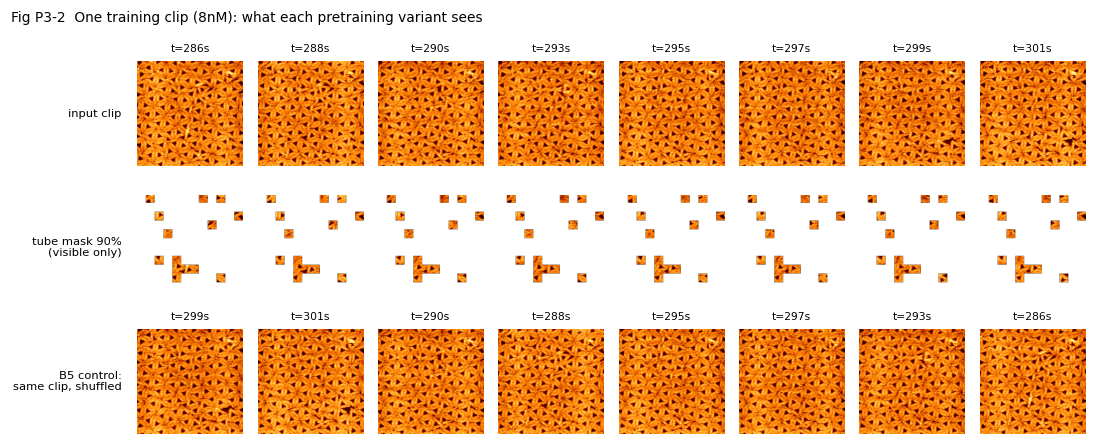

In [8]:
# ---- 7. Visual: what the model sees during pretraining (Fig P3-2) -----------------------------------------------
gen_np = np.random.default_rng(SEED)
smp = ClipSampler(CONCS, T_FRAMES, MAX_OFFSET, gen_np)
ia, ib = smp.sample_idx(1)
xa, = crop_aug([ia], CROP, train=False)
perm_demo = np.random.default_rng(3).permutation(T_FRAMES)
xs = xa[:, :, perm_demo]
demo = VideoMAE(T=T_FRAMES, tubelet=TUBELET).to(DEVICE)
_, mask_demo = demo.make_mask(1, MASK_TUBE, True, torch.Generator(device=DEVICE).manual_seed(1))
mimg = demo.unpatchify(mask_demo[..., None].expand(-1, -1, TUBELET * PATCH * PATCH))[0, 0].cpu().numpy()
del demo
fig, axes = plt.subplots(3, T_FRAMES, figsize=(1.25 * T_FRAMES, 4.1))
tt_ = kept.loc[ia[0].cpu().numpy(), 't_rel_s'].values
for t in range(T_FRAMES):
    im = xa[0, 0, t].cpu().numpy()
    axes[0, t].imshow(im, cmap='afmhot', vmin=-2, vmax=2); axes[0, t].set_title(f't={tt_[t]:.0f}s', fontsize=7)
    axes[1, t].imshow(np.where(mimg[t] > 0.5, np.nan, im), cmap='afmhot', vmin=-2, vmax=2)
    axes[2, t].imshow(xs[0, 0, t].cpu().numpy(), cmap='afmhot', vmin=-2, vmax=2); axes[2, t].set_title(f't={tt_[perm_demo[t]]:.0f}s', fontsize=7)
    for r in range(3): axes[r, t].axis('off')
for r, lab in enumerate(['input clip', f'tube mask {int(MASK_TUBE*100)}%\n(visible only)', 'B5 control:\nsame clip, shuffled']):
    axes[r, 0].text(-0.15, 0.5, lab, transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=7.5)
fig.suptitle(f'Fig P3-2  One training clip ({kept.conc[int(ia[0,0])]}): what each pretraining variant sees', fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP3_2_clip_and_masking.png'), bbox_inches='tight'); plt.show()

In [9]:
# ---- 8. Pretraining (resumable; one run per split x variant) ------------------------------------------------------
all_splits = splits_p1['splits']
SPLIT_LIST = list(all_splits) if SPLITS == 'all' else list(SPLITS)
SPLIT_LIST = [s for s in SPLIT_LIST if s in all_splits]

def lr_at(step):
    if step < WARMUP:
        return LR * (step + 1) / WARMUP
    q = (step - WARMUP) / max(1, STEPS - WARMUP)
    return LR * 0.5 * (1 + math.cos(math.pi * min(1.0, q)))

def run_dir(split, variant):
    return os.path.join(RUNS, f'{split}__{variant}')

def train_one(split, variant):
    rd = run_dir(split, variant); os.makedirs(rd, exist_ok=True)
    ck, done = os.path.join(rd, 'ckpt.pt'), os.path.join(rd, 'final.pt')
    train_concs = all_splits[split]['train']
    mj = os.path.join(rd, 'meta.json')
    if os.path.exists(done):
        meta = json.load(open(mj)) if os.path.exists(mj) else {}
        if sorted(meta.get('train_concs', [])) == sorted(train_concs) and meta.get('QUICK') == QUICK and meta.get('step') == STEPS:
            return 'done'
        print(f'   {split} {variant}: finished run used other data/settings -> retraining')
        os.remove(done)
        if os.path.exists(ck): os.remove(ck)
    seed_all(SEED); gen = np.random.default_rng(SEED + zlib.crc32((split + variant).encode()) % 100000)
    gen_t = torch.Generator(device=DEVICE).manual_seed(SEED)
    model = make_model(variant).to(DEVICE)
    try:
        opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WD, fused=DEVICE.type == 'cuda')
    except (TypeError, RuntimeError):
        opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WD)
    scaler = torch.amp.GradScaler('cuda', enabled=(USE_AMP and AMP_DTYPE == torch.float16))
    step, log = 0, []
    if os.path.exists(ck):
        st = torch.load(ck, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); step = st['step']; log = st['log']
        print(f'   resumed at step {step}')
    if variant == 'B2':
        sampler = ClipSampler(train_concs, 1, 0, gen)
    else:
        sampler = ClipSampler(train_concs, T_FRAMES, MAX_OFFSET, gen)
    model.train(); t0 = time.time(); acc = []
    while step < STEPS:
        for g_ in opt.param_groups:
            g_['lr'] = lr_at(step)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            if variant == 'B2':
                ia, _ = sampler.sample_idx(BATCH_FRAMES)
                xa, = crop_aug([ia], CROP, True, gen)
                loss_rec, _, _, _, _ = model.forward_mae(xa, MASK_FRAME, False, gen_t)
                loss_nce = torch.zeros((), device=DEVICE); loss = loss_rec
            else:
                ia, ib = sampler.sample_idx(BATCH_PAIRS)
                xa, xb = crop_aug([ia, ib], CROP, True, gen, shuffle_time=(variant == 'B5'))
                x = torch.cat([xa, xb])
                loss_rec, lat, _, _, _ = model.forward_mae(x, MASK_TUBE, True, gen_t)
                if variant in ('B4', 'B5'):
                    z = model.proj(lat.mean(1))
                    loss_nce = info_nce(z[:BATCH_PAIRS], z[BATCH_PAIRS:])
                else:
                    loss_nce = torch.zeros((), device=DEVICE)
                loss = loss_rec + (LAMBDA_NCE * loss_nce if variant in ('B4', 'B5') else 0.0)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        acc.append((float(loss_rec.detach()), float(loss_nce.detach())))
        step += 1
        if step % LOG_EVERY == 0 or step == STEPS:
            r, n = np.mean(acc, axis=0); acc = []
            log.append(dict(step=step, loss_rec=r, loss_nce=n, lr=lr_at(step), sec=time.time() - t0))
        if step % CKPT_EVERY == 0 and step < STEPS:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), step=step, log=log), ck)
    torch.save(dict(model=model.state_dict(), step=step, log=log, variant=variant, split=split,
                    train_concs=train_concs, config=dict(CROP=CROP, PATCH=PATCH, ENC_DIM=ENC_DIM, ENC_DEPTH=ENC_DEPTH,
                                                         T=T_FRAMES, QUICK=QUICK, STEPS=STEPS)), done)
    pd.DataFrame(log).to_csv(os.path.join(rd, 'log.csv'), index=False)
    json.dump(dict(train_concs=list(train_concs), QUICK=QUICK, step=step, variant=variant, split=split,
                   finished=datetime.now().isoformat(timespec='seconds')), open(mj, 'w'))
    if os.path.exists(ck):
        os.remove(ck)
    del model, opt
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return f'{time.time()-t0:.0f}s'

jobs = [(s, v) for s in SPLIT_LIST for v in VARIANTS]
print(f'{len(jobs)} pretraining runs: {len(SPLIT_LIST)} splits x {len(VARIANTS)} variants')
t_all = time.time(); n_new = 0
for k, (s, v) in enumerate(jobs):
    t1 = time.time(); res = train_one(s, v)
    if res != 'done':
        n_new += 1
        eta = (time.time() - t_all) / n_new * (len(jobs) - k - 1)
        print(f'[{k+1}/{len(jobs)}] {s:16s} {v}  trained in {res}   ETA for the rest ~{eta/60:.0f} min')
    else:
        print(f'[{k+1}/{len(jobs)}] {s:16s} {v}  already finished')

28 pretraining runs: 7 splits x 4 variants
[1/28] LOCO_2nM         B2  already finished
[2/28] LOCO_2nM         B3  already finished
[3/28] LOCO_2nM         B4  already finished
[4/28] LOCO_2nM         B5  already finished
[5/28] LOCO_4nM         B2  already finished
[6/28] LOCO_4nM         B3  already finished
[7/28] LOCO_4nM         B4  already finished
[8/28] LOCO_4nM         B5  already finished
[9/28] LOCO_6nM         B2  already finished
[10/28] LOCO_6nM         B3  already finished
[11/28] LOCO_6nM         B4  already finished
[12/28] LOCO_6nM         B5  already finished
[13/28] LOCO_8nM         B2  already finished
[14/28] LOCO_8nM         B3  already finished
[15/28] LOCO_8nM         B4  already finished
[16/28] LOCO_8nM         B5  already finished
[17/28] LOCO_10nM        B2  already finished
[18/28] LOCO_10nM        B3  already finished
[19/28] LOCO_10nM        B4  already finished
[20/28] LOCO_10nM        B5  already finished
   resumed at step 1500
[21/28] P1_low_to_high

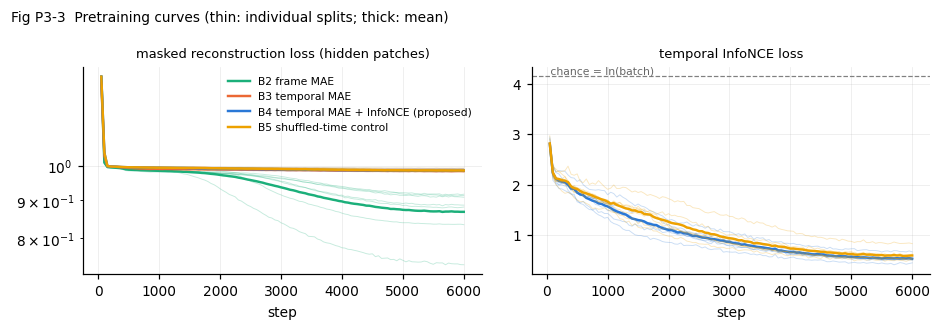

In [10]:
# ---- 9. Training curves (Fig P3-3) --------------------------------------------------------------------------------
logs = []
for s, v in jobs:
    f = os.path.join(run_dir(s, v), 'log.csv')
    if os.path.exists(f):
        d = pd.read_csv(f); d['split'] = s; d['variant'] = v; logs.append(d)
logs = pd.concat(logs, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.0))
for v in VARIANTS:
    d = logs[logs.variant == v]
    for s, g in d.groupby('split'):
        axes[0].plot(g.step, g.loss_rec, color=VCOL[v], lw=0.6, alpha=0.25)
        if v in ('B4', 'B5'):
            axes[1].plot(g.step, g.loss_nce, color=VCOL[v], lw=0.6, alpha=0.25)
    m = d.groupby('step')[['loss_rec', 'loss_nce']].mean()
    axes[0].plot(m.index, m.loss_rec, color=VCOL[v], label=VNAME[v])
    if v in ('B4', 'B5'):
        axes[1].plot(m.index, m.loss_nce, color=VCOL[v], label=VNAME[v])
axes[0].set_title('masked reconstruction loss (hidden patches)', fontsize=8.5); axes[0].set_yscale('log')
axes[1].set_title('temporal InfoNCE loss', fontsize=8.5)
axes[1].axhline(np.log(BATCH_PAIRS), color='0.5', ls='--', lw=0.8); axes[1].text(0, np.log(BATCH_PAIRS), ' chance = ln(batch)', fontsize=7, va='bottom', color='0.4')
for a in axes: a.set_xlabel('step')
axes[0].legend(fontsize=7)
fig.suptitle('Fig P3-3  Pretraining curves (thin: individual splits; thick: mean)', fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP3_3_training_curves.png'), bbox_inches='tight'); plt.show()
final_loss = logs.sort_values('step').groupby(['split', 'variant']).tail(1)
first_loss = logs.sort_values('step').groupby(['split', 'variant']).head(1)

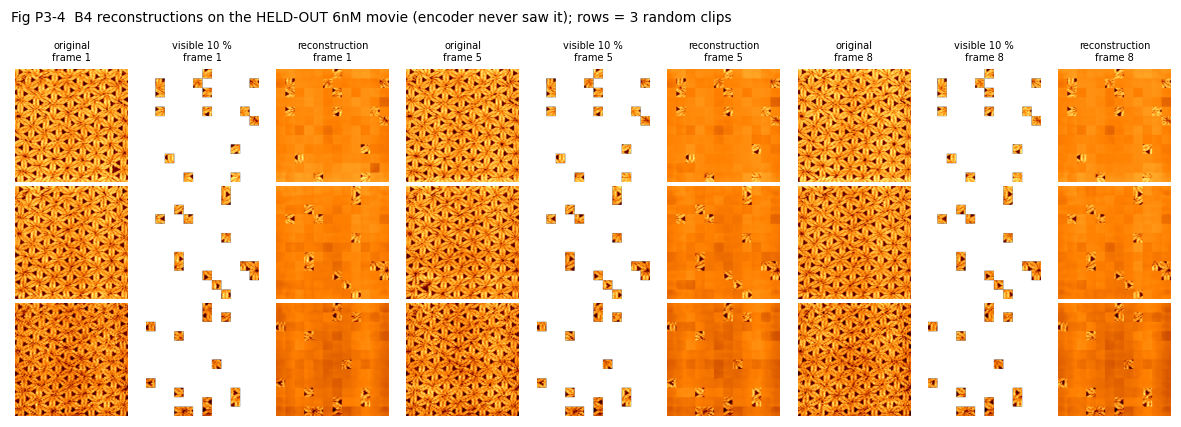

In [11]:
# ---- 10. Reconstructions of a HELD-OUT movie by the proposed model (Fig P3-4) -------------------------------------------
def load_model(split, variant):
    m = make_model(variant).to(DEVICE)
    if variant != 'B0':
        st = torch.load(os.path.join(run_dir(split, variant), 'final.pt'), map_location=DEVICE, weights_only=False)
        m.load_state_dict(st['model'])
    else:
        torch.manual_seed(SEED); m = make_model('B4').to(DEVICE)          # fixed random initialisation
    return m.eval()

loco = [s for s in SPLIT_LIST if s.startswith('LOCO_')]
show_split = 'LOCO_6nM' if 'LOCO_6nM' in loco else (loco[0] if loco else SPLIT_LIST[0])
test_c = all_splits[show_split]['test'][0]
if 'B4' in VARIANTS:
    m4 = load_model(show_split, 'B4')
    smp_t = ClipSampler([test_c], T_FRAMES, 0, np.random.default_rng(5))
    ia, _ = smp_t.sample_idx(3)
    x, = crop_aug([ia], CROP, train=False)
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        _, _, pred, mask, (mu, var) = m4.forward_mae(x, MASK_TUBE, True, torch.Generator(device=DEVICE).manual_seed(2))
    rec = m4.unpatchify(pred.float() * (var + 1e-6).sqrt() + mu)
    mimg = m4.unpatchify(mask[..., None].expand(-1, -1, TUBELET * PATCH * PATCH))
    tsel = [0, T_FRAMES // 2, T_FRAMES - 1]
    fig, axes = plt.subplots(3, 3 * len(tsel), figsize=(1.2 * 3 * len(tsel), 3.9))
    for r in range(3):
        for j, t in enumerate(tsel):
            orig = x[r, 0, t].cpu().numpy(); mm = mimg[r, 0, t].cpu().numpy() > 0.5
            comp = np.where(mm, rec[r, 0, t].cpu().numpy(), orig)
            for k, (im, lab) in enumerate([(orig, 'original'), (np.where(mm, np.nan, orig), 'visible 10 %'), (comp, 'reconstruction')]):
                a = axes[r, 3 * j + k]; a.imshow(im, cmap='afmhot', vmin=-2, vmax=2); a.axis('off')
                if r == 0: a.set_title(f'{lab}\nframe {t+1}', fontsize=6.5)
    fig.suptitle(f'Fig P3-4  B4 reconstructions on the HELD-OUT {test_c} movie (encoder never saw it); rows = 3 random clips',
                 fontsize=9, x=0.01, ha='left')
    fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP3_4_reconstructions_heldout.png'), bbox_inches='tight'); plt.show()
    del m4

In [12]:
# ---- 11. Per-frame embeddings for every split x variant (incl. B0) -> Portion 4 -----------------------------------------
def causal_indices(T, frame_rows):
    """(n,T) global indices: clip of T frames ENDING at each frame (earlier frames repeated at the session start)."""
    out = np.zeros((len(frame_rows), T), int)
    for i, (g, s) in enumerate(zip(frame_rows.index.values, frame_rows.session.values)):
        v = SESS[s]; p = int(kept.at[g, 'pos'])
        pos = np.clip(p - v['stride'] * np.arange(T - 1, -1, -1), 0, None)
        out[i] = v['gidx'][pos]
    return out

IDX_T = causal_indices(T_FRAMES, kept)
IDX_1 = causal_indices(1, kept)

def extract(model, variant):
    idx = IDX_1 if variant == 'B2' else IDX_T
    Z = []
    for i in range(0, len(idx), EMB_BATCH):
        x, = crop_aug([torch.as_tensor(idx[i:i + EMB_BATCH], device=DEVICE)], CROP, train=False)
        with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            Z.append(model.embed(x).float().cpu().numpy())
    return np.concatenate(Z).astype(np.float32)

EMB_VARIANTS = ['B0'] + VARIANTS
t0 = time.time()
for s in SPLIT_LIST:
    os.makedirs(os.path.join(EMB, s), exist_ok=True)
    for v in EMB_VARIANTS:
        f = os.path.join(EMB, s, f'{v}.npz')
        if os.path.exists(f):
            old = np.load(f, allow_pickle=True)
            fresh = (len(old['frame_id']) == len(kept) and sorted(old['train_concs']) == sorted(all_splits[s]['train'])
                     and (v == 'B0' or os.path.getmtime(f) >= os.path.getmtime(os.path.join(run_dir(s, v), 'final.pt'))))
            if fresh:
                continue
        m = load_model(s, v); Z = extract(m, v); del m
        np.savez_compressed(f, Z=Z, frame_id=kept.frame_id.values.astype(str), split=s, variant=v,
                            train_concs=np.array(all_splits[s]['train']), test_concs=np.array(all_splits[s]['test']))
print(f'embeddings ready ({time.time()-t0:.0f}s): {len(SPLIT_LIST)} splits x {len(EMB_VARIANTS)} variants')

embeddings ready (157s): 7 splits x 5 variants


In [13]:
# ---- 12. Linear probes on held-out movies (LOCO) --------------------------------------------------------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

T2 = targets.set_index('frame_id')
lab = kept[['frame_id', 'conc', 't_rel_s']].join(T2[['coverage', 'fft_peak_ratio', 'fft_psi6', 'density_um2',
                                                     'regime', 'lattice_valid', 'count_valid', 'contrast_ok']], on='frame_id')
# start-up / unstable-tip frames (Portion 1 warn_streaks) have artefactual measurements -> not used as probe labels
streak = kept.frame_id.map(frames.set_index('frame_id').warn_streaks).fillna(False).astype(bool).values
lab.loc[streak, ['coverage', 'fft_peak_ratio', 'fft_psi6', 'density_um2']] = np.nan
lab.loc[streak, 'regime'] = 'excluded'
print(f'{int(streak.sum())} streak-flagged frames excluded from probe labels')
# dynamics label: coverage change over the next 30 s (same movie)
fut = []
for c, g in lab.groupby('conc'):
    tt, cv = g.t_rel_s.values, g.coverage.values
    j = np.searchsorted(tt, tt + 30.0).clip(0, len(tt) - 1)
    ok = np.abs(tt[j] - (tt + 30.0)) <= 5.0
    fut.append(pd.Series(np.where(ok, cv[j] - cv, np.nan), index=g.index))
lab['dcov_30s'] = pd.concat(fut)
PROBES = {   # name: (column, transform, valid-mask column or None, kind)
    'coverage':          ('coverage', None, 'contrast_ok', 'reg'),
    'lattice sharpness': ('fft_peak_ratio', np.log, None, 'reg'),
    'ψ6 (dense)':        ('fft_psi6', None, 'lattice_valid', 'reg'),
    'density (sparse)':  ('density_um2', np.log1p, 'count_valid', 'reg'),
    'Δcoverage +30 s':   ('dcov_30s', None, None, 'reg'),
    'regime':            ('regime', None, 'contrast_ok', 'cls'),
}

def ridge_path(A, y, alphas):
    """closed-form ridge for several alphas from ONE eigen-decomposition of A^T A (fast)."""
    Ac = A - A.mean(0); yc = y - y.mean()
    ev, V = np.linalg.eigh(Ac.T @ Ac); r = V.T @ (Ac.T @ yc)
    return [(V @ (r / (ev + al)), y.mean(), A.mean(0)) for al in alphas]

def ridge_fit_predict(Xtr, ytr, Xte, groups, alphas=(1, 10, 100, 1000, 10000)):
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    A, B = (Xtr - mu) / sd, (Xte - mu) / sd
    err = np.zeros(len(alphas)); ug = np.unique(groups)
    if len(ug) >= 2:                                   # alpha by leave-one-concentration-out INSIDE the training set
        for gg in ug:
            tr = groups != gg
            for k, (w, b, m) in enumerate(ridge_path(A[tr], ytr[tr], alphas)):
                err[k] += np.mean(np.abs((A[~tr] - m) @ w + b - ytr[~tr]))
    w, b, m = ridge_path(A, ytr, [alphas[int(np.argmin(err))]])[0]
    return (B - m) @ w + b

def knn_predict(Xtr, ytr, Xte, k=10):
    a = Xtr / (np.linalg.norm(Xtr, axis=1, keepdims=True) + 1e-9); b = Xte / (np.linalg.norm(Xte, axis=1, keepdims=True) + 1e-9)
    nn_ = np.argsort(-(b @ a.T), axis=1)[:, :k]
    return ytr[nn_].mean(1)

probe_rows, oof = [], []
for s in loco:
    tr_c, te_c = all_splits[s]['train'], all_splits[s]['test']
    for v in EMB_VARIANTS:
        d = np.load(os.path.join(EMB, s, f'{v}.npz')); Z = d['Z']
        assert set(te_c).isdisjoint(set(d['train_concs'])), 'leakage: test concentration in pretraining set'
        for pname, (col, fn, vm, kind) in PROBES.items():
            ok = lab[col].notna().values
            if vm is not None:
                ok &= lab[vm].astype(bool).values
            if kind == 'cls':
                ok &= lab[col].isin(['sparse', 'transition', 'dense']).values
            tr = ok & lab.conc.isin(tr_c).values; te = ok & lab.conc.isin(te_c).values
            if tr.sum() < 20 or te.sum() < 5:
                continue
            if kind == 'reg':
                y = lab[col].values.astype(float); y = fn(y) if fn is not None else y
                p = ridge_fit_predict(Z[tr], y[tr], Z[te], lab.conc.values[tr])
                pk = knn_predict(Z[tr], y[tr], Z[te])
                probe_rows.append(dict(split=s, test=te_c[0], variant=v, probe=pname, metric='MAE',
                                       value=float(np.mean(np.abs(p - y[te]))), knn_MAE=float(np.mean(np.abs(pk - y[te]))), n=int(te.sum())))
                oof.append(pd.DataFrame(dict(variant=v, probe=pname, y=y[te], p=p, conc=te_c[0])))
            else:
                yc = lab[col].values
                mu, sd = Z[tr].mean(0), Z[tr].std(0) + 1e-6
                clf = LogisticRegression(max_iter=2000, class_weight='balanced', C=0.1)
                clf.fit((Z[tr] - mu) / sd, yc[tr]); pc = clf.predict((Z[te] - mu) / sd)
                probe_rows.append(dict(split=s, test=te_c[0], variant=v, probe=pname, metric='balanced acc.',
                                       value=float(balanced_accuracy_score(yc[te], pc)), knn_MAE=np.nan, n=int(te.sum())))
probe = pd.DataFrame(probe_rows)
oof = pd.concat(oof, ignore_index=True) if oof else pd.DataFrame(columns=['variant', 'probe', 'y', 'p', 'conc'])
probe.to_csv(os.path.join(OUT_DIR, 'probe_results_per_fold.csv'), index=False)
pooled = []
for (v, pn), g in oof.groupby(['variant', 'probe']):
    ss_res = np.sum((g.y - g.p) ** 2); ss_tot = np.sum((g.y - g.y.mean()) ** 2)
    pooled.append(dict(variant=v, probe=pn, pooled_R2=1 - ss_res / ss_tot if ss_tot > 0 else np.nan))
pooled = pd.DataFrame(pooled)
summary = probe.groupby(['probe', 'variant'])['value'].agg(['mean', 'std', 'count']).round(4)
display(summary.unstack('variant')['mean'])
pooled.to_csv(os.path.join(OUT_DIR, 'probe_pooled_R2.csv'), index=False)

87 streak-flagged frames excluded from probe labels


variant,B0,B2,B3,B4,B5
probe,,,,,
coverage,0.1269,0.0799,0.0402,0.0557,0.0466
density (sparse),0.1139,0.2495,0.1795,0.2081,0.2177
lattice sharpness,0.4045,0.4057,0.4358,0.4033,0.3945
regime,0.9068,0.9492,0.9199,0.9596,0.9404
Δcoverage +30 s,0.0297,0.0325,0.0360,0.0361,0.0403
ψ6 (dense),0.1488,0.1434,0.1552,0.1542,0.1516


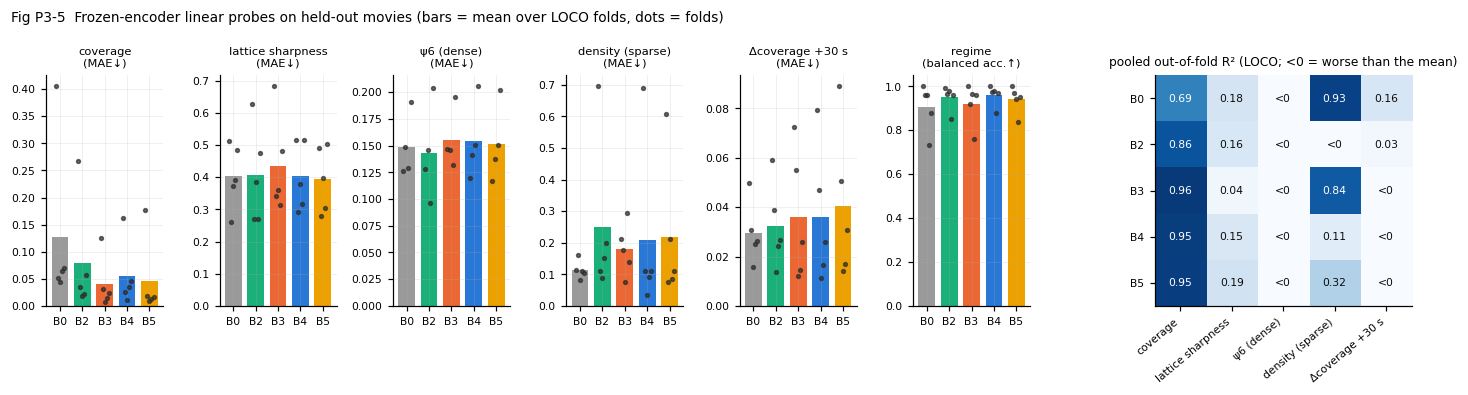

In [14]:
# ---- 13. Probe figure (Fig P3-5): per-fold dots + pooled R2 heatmap ----------------------------------------------------------
pnames = [p for p in PROBES if p in probe.probe.unique()]
fig = plt.figure(figsize=(13, 3.6))
gs = fig.add_gridspec(1, len(pnames) + 2, width_ratios=[1] * len(pnames) + [0.1, 2.2])
for k, pn in enumerate(pnames):
    ax = fig.add_subplot(gs[0, k]); d = probe[probe.probe == pn]
    for j, v in enumerate(EMB_VARIANTS):
        dv = d[d.variant == v]
        if dv.empty: continue
        ax.bar(j, dv['value'].mean(), color=VCOL[v], width=0.75)
        ax.plot(np.full(len(dv), j) + np.linspace(-0.18, 0.18, len(dv)), dv['value'], 'o', ms=2.5, color='#2b2b2b', alpha=0.7)
    ax.set_xticks(range(len(EMB_VARIANTS))); ax.set_xticklabels(EMB_VARIANTS, fontsize=7)
    ax.set_title(f'{pn}\n({d.metric.iloc[0]}{"↓" if d.metric.iloc[0]=="MAE" else "↑"})', fontsize=7.5)
    ax.tick_params(axis='y', labelsize=7)
axh = fig.add_subplot(gs[0, -1])
if not pooled.empty:
    hm = pooled.pivot(index='variant', columns='probe', values='pooled_R2').reindex(index=EMB_VARIANTS)
    hm = hm[[p for p in pnames if p in hm.columns]]
    im = axh.imshow(hm.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    axh.set_xticks(range(hm.shape[1])); axh.set_xticklabels(hm.columns, rotation=40, ha='right', fontsize=7)
    axh.set_yticks(range(hm.shape[0])); axh.set_yticklabels(hm.index, fontsize=7); axh.grid(False)
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            val = hm.values[i, j]
            axh.text(j, i, '–' if np.isnan(val) else ('<0' if val < 0 else f'{val:.2f}'), ha='center', va='center', fontsize=7,
                     color='white' if (not np.isnan(val) and val > 0.6) else '#0b0b0b')
    axh.set_title('pooled out-of-fold R² (LOCO; <0 = worse than the mean)', fontsize=8)
fig.suptitle('Fig P3-5  Frozen-encoder linear probes on held-out movies (bars = mean over LOCO folds, dots = folds)',
             fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP3_5_linear_probes.png'), bbox_inches='tight'); plt.show()

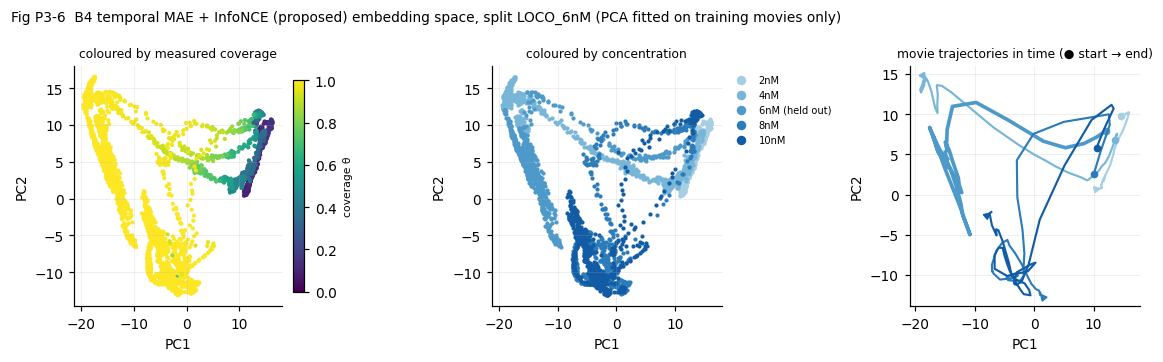

In [15]:
# ---- 14. Learned state space (Fig P3-6): PCA trajectories of every movie -------------------------------------------------------
v_show = 'B4' if 'B4' in VARIANTS else VARIANTS[-1]
d = np.load(os.path.join(EMB, show_split, f'{v_show}.npz')); Z = d['Z']
trm = lab.conc.isin(all_splits[show_split]['train']).values
mu = Z[trm].mean(0); U, S_, Vt = np.linalg.svd(Z[trm] - mu, full_matrices=False)
P = (Z - mu) @ Vt[:2].T
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3))
sc = axes[0].scatter(P[:, 0], P[:, 1], c=lab.coverage, cmap='viridis', s=3, vmin=0, vmax=1)
plt.colorbar(sc, ax=axes[0], fraction=0.046).set_label('coverage θ', fontsize=7)
for c in CONCS:
    m_ = (lab.conc == c).values
    axes[1].scatter(P[m_, 0], P[m_, 1], s=3, color=CCOL.get(c, 'k'), label=c + (' (held out)' if c == test_c else ''))
    g = lab[m_].sort_values('t_rel_s'); pp = P[g.index.values]
    k_ = max(1, len(pp) // 40); sm = pd.DataFrame(pp).rolling(k_ * 3, min_periods=1, center=True).mean().values[::k_]
    axes[2].plot(sm[:, 0], sm[:, 1], color=CCOL.get(c, 'k'), lw=1.4 if c != test_c else 2.4, label=c)
    if len(sm) > 1:
        axes[2].annotate('', xy=sm[-1], xytext=sm[-2], arrowprops=dict(arrowstyle='-|>', color=CCOL.get(c, 'k'), lw=1.2))
        axes[2].plot(*sm[0], 'o', ms=4, color=CCOL.get(c, 'k'))
axes[1].legend(fontsize=6.5, markerscale=3, loc='upper left', bbox_to_anchor=(1.0, 1.0))
for a, t in zip(axes, ['coloured by measured coverage', 'coloured by concentration', 'movie trajectories in time (● start → end)']):
    a.set_title(t, fontsize=8); a.set_xlabel('PC1'); a.set_ylabel('PC2')
fig.suptitle(f'Fig P3-6  {VNAME[v_show]} embedding space, split {show_split} (PCA fitted on training movies only)', fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP3_6_embedding_trajectories.png'), bbox_inches='tight'); plt.show()

In [16]:
# ---- 15. Checks & summary --------------------------------------------------------------------------------------------------------
def mean_probe(v, pn):
    d = probe[(probe.variant == v) & (probe.probe == pn)]
    return d['value'].mean() if len(d) else np.nan
checks = []
n_final = sum(os.path.exists(os.path.join(run_dir(s, v), 'final.pt')) for s, v in jobs)
checks.append(('All pretraining runs finished', 'PASS' if n_final == len(jobs) else 'FAIL', f'{n_final}/{len(jobs)}'))
fl = final_loss.set_index(['split', 'variant']).loss_rec.sort_index(); il = first_loss.set_index(['split', 'variant']).loss_rec.reindex(fl.index)
checks.append(('Reconstruction loss decreased in every run', 'PASS' if (fl < il).all() else 'CHECK', f'{int((fl < il).sum())}/{len(fl)}'))
lk = all(set(np.load(os.path.join(EMB, s, f'{v}.npz'))['train_concs']).isdisjoint(all_splits[s]['test'])
         for s in SPLIT_LIST for v in EMB_VARIANTS)
checks.append(('No held-out movie used in pretraining', 'PASS' if lk else 'FAIL', 'checked for every split x variant'))
if 'B4' in VARIANTS:
    for pn in ['coverage', 'Δcoverage +30 s']:
        b4, b0 = mean_probe('B4', pn), mean_probe('B0', pn)
        checks.append((f'H1: B4 beats random init on "{pn}" probe (MAE)', 'SUPPORTED' if b4 < b0 else 'NOT SUPPORTED', f'{b4:.4f} vs {b0:.4f}'))
    if 'B5' in VARIANTS:
        b4, b5 = mean_probe('B4', 'Δcoverage +30 s'), mean_probe('B5', 'Δcoverage +30 s')
        checks.append(('H2: true time order helps dynamics probe (B4 < B5)', 'SUPPORTED' if b4 < b5 else 'NOT SUPPORTED', f'{b4:.4f} vs {b5:.4f}'))
    if 'B3' in VARIANTS:
        b4, b3 = mean_probe('B4', 'coverage'), mean_probe('B3', 'coverage')
        checks.append(('H3: temporal InfoNCE adds to temporal MAE (coverage probe)', 'SUPPORTED' if b4 < b3 else 'NOT SUPPORTED', f'{b4:.4f} vs {b3:.4f}'))
C = pd.DataFrame(checks, columns=['check', 'status', 'detail']); display(C)
C.to_csv(os.path.join(OUT_DIR, 'checks_portion3.csv'), index=False)
json.dump(dict(created=datetime.now().isoformat(timespec='seconds'), QUICK=QUICK, device=str(DEVICE), torch=torch.__version__,
               variants=VARIANTS, splits=SPLIT_LIST, config={k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, bool))}),
          open(os.path.join(OUT_DIR, 'run_config_portion3.json'), 'w'), indent=1, default=str)
if QUICK:
    print('\nQUICK mode: these numbers only prove the pipeline runs. Delete portion3_outputs/runs and embeddings, switch to an A100 runtime, and re-run.')
print('Outputs:', sorted(os.listdir(OUT_DIR)))

,check,status,detail
0,All pretraining runs finished,PASS,28/28
1,Reconstruction loss decreased in every run,PASS,28/28
2,No held-out movie used in pretraining,PASS,checked for every split x variant
3,"H1: B4 beats random init on ""coverage"" probe (...",SUPPORTED,0.0557 vs 0.1269
4,"H1: B4 beats random init on ""Δcoverage +30 s"" ...",NOT SUPPORTED,0.0361 vs 0.0297
5,H2: true time order helps dynamics probe (B4 <...,SUPPORTED,0.0361 vs 0.0403
6,H3: temporal InfoNCE adds to temporal MAE (cov...,NOT SUPPORTED,0.0557 vs 0.0402


Outputs: ['checks_portion3.csv', 'dataset_5nm_f16.npy', 'dataset_index.csv', 'embeddings', 'figures', 'probe_pooled_R2.csv', 'probe_results_per_fold.csv', 'run_config_portion3.json', 'runs']


## What you have now (`portion3_outputs/`)
| File | Use |
|---|---|
| `runs/<split>__<variant>/final.pt`, `log.csv` | frozen encoders + training logs (one per split × variant) |
| `embeddings/<split>/<variant>.npz` | per-frame embeddings `Z` (rows = `frame_id`) for Portion 4; each file records its training concentrations |
| `probe_results_per_fold.csv`, `probe_pooled_R2.csv` | representation quality on held-out movies (LOCO) |
| `figures/figP3_*.png` | architecture, masking, training curves, held-out reconstructions, probes, embedding trajectories |
| `checks_portion3.csv` | completion/leakage checks and the first evidence for H1–H3 |

**Hypotheses are reported honestly:** "NOT SUPPORTED" is a valid scientific result, not a bug. Portion 4 tests the same models on the real task (forecasting).
**If Colab disconnects:** just re-run all cells — finished runs are skipped and unfinished runs resume from the last checkpoint.